# Customer Churn Prediction and Retention-Budget Optimization
### An end-to-end analysis of churn, time-to-first-purchase (time-to-return), and retention-budget allocation on real e-commerce data

**Data.** Open E-Commerce 1.0 (Berke et al., 2024, Scientific Data,
DOI 10.1038/s41597-024-03329-6) - 1,761,259 real Amazon purchase records (2018-01 to
2023-03) and 5,027 demographic survey respondents, aggregated to a 5,013-customer
analysis table.

---

## Abstract

Customer churn is the loss of recurring value that retention programmes aim to
prevent. This analysis (i) predicts which customers lapse within a 90-day window,
(ii) explains the drivers of lapse, (iii) models the time to first purchase (time-to-return)
with survival analysis, and (iv) allocates a limited retention budget exactly, so that
expected retained value is maximized. Every model is validated on a future period it
never saw (survival probabilities carry an in-sample note - see 7.1).

## Methodology and integrity

1. **Temporal validation.** The train period ends 2022-03-19 and the test period begins
   2022-09-19. The windows are disjoint in time, every outcome window is fully observed,
   and no feature uses post-cutoff information.
2. **Churn definition.** Churn is defined as no purchase within N days, with N = 90 as
   the primary window and N in {30, 60, 120, 180} used for sensitivity analysis.
3. **Leakage control.** Features are computed from orders before each cutoff. CLV is
   winsorized at the 99th percentile and multicollinearity is checked with VIF.
4. **Business metric.** Precision at the top-10% score decile is the primary targeting
   metric, because churn is rare (about 10%) and accuracy alone is not informative.
5. **Ethics.** Only benign demographic and Amazon-usage survey items are used. Sensitive
   health and substance-use items are excluded.

**Reproduction.**
```
python build_dataset.py      # raw data -> customer table + temporal snapshots + survival labels
python build_notebook.py     # rebuild this notebook
python execute_notebook.py   # execute in place
python train_models.py       # models and artifacts for the dashboard
streamlit run dashboard.py   # interactive dashboard
```




## 1. Business Problem and Data

### 1.1 Objective

Retention is the highest-leverage growth lever in e-commerce. The objective is to
predict which customers stop purchasing within the next 90 days, explain why they
disengage, and allocate a limited retention budget so that every dollar protects the
most customer value.

| Task | Type | Target | Business use |
|:--|:--|:--|:--|
| A. Predict churn in the next 90 days | Classification | no purchase in 90 days | early-warning list for retention offers |
| B. Diagnose disengagement drivers | Interpretation | model evidence | root causes: category mix, AOV trend, demographics |
| C. Segment customers | Unsupervised | behaviour clusters | tiered win-back strategies |
| D. Optimize the retention budget | Optimization | retained value | maximum retained revenue under a fixed budget |

### 1.2 Performance measures and success criteria

* ROC-AUC at least 0.85 on the temporal test period, where the base churn rate is about
  10 percent.
* Precision at the top-10% score decile at least 3x the base rate, which measures
  targeting quality rather than ranking only.
* AUC stable within a small range across 30 to 180 day churn windows, which shows that
  the signal does not depend on the cutoff.
* An offer allocation whose retained value per budget dollar exceeds a naive baseline.


In [1]:
import pickle, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier, VotingClassifier)
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
RANDOM_STATE = 42

tr = pd.read_csv("data/snapshot_train.csv")
te = pd.read_csv("data/snapshot_test.csv")
cust = pd.read_csv("data/customers.csv")
print(f"Train snapshot (cutoff 2022-03-19): {len(tr):,} customers, 90d churn {tr.label_churn.mean():.1%}")
print(f"Test  snapshot (cutoff 2022-09-19): {len(te):,} customers, 90d churn {te.label_churn.mean():.1%}")
print(f"Customer table (full history)     : {len(cust):,} x {cust.shape[1]}")
print("\nMissing (train):", tr.isna().sum()[tr.isna().sum() > 0].to_dict() or "none")
tr.head()

Train snapshot (cutoff 2022-03-19): 4,857 customers, 90d churn 10.9%
Test  snapshot (cutoff 2022-09-19): 4,850 customers, 90d churn 9.9%
Customer table (full history)     : 5,013 x 21

Missing (train): {'aov_recent': 441, 'aov_prior': 434, 'Annual_Income_USD': 69, 'aov_trend': 701}


,Customer_ID,orders_12m,spend_12m,aov_12m,aov_recent,aov_prior,recency_days,active_months_12m,category_count_12m,avg_price_12m,entertainment_share,gaming_share,media_share,gift_card_share,ott_flag,Age,Annual_Income_USD,Gender,Education_Level,Household_Size,Race_Group,Hispanic,Reported_Usage_Freq,Region,aov_trend,label_churn_30,label_churn_60,label_churn_90,label_churn_120,label_churn_180,label_churn
0,R_01vNIayewjIIKMF,38,2447.05,64.396053,20.578125,123.775000,28,9,19,63.693684,0.197381,0.197381,0.000000,0.000000,0.0,39.5,37500.0,Male,Bachelor's,1,Black only,1,1,Northeast,-103.196875,1,0,0,0,0,0
1,R_037XK72IZBJyF69,469,6428.24,13.706269,17.503068,24.788036,2,13,204,13.392324,0.000000,0.000000,0.012448,0.021779,0.0,59.5,37500.0,Female,Bachelor's,2,White only,0,1,Northeast,-7.284968,0,0,0,0,0,0
2,R_038ZU6kfQ5f89fH,23,2147.83,93.383913,66.708000,46.077500,24,5,12,73.427391,0.008325,0.008325,0.000000,0.000000,0.0,29.5,37500.0,Male,High School or Less,1,White only,0,1,West,20.630500,1,1,1,1,1,1
3,R_03aEbghUILs9NxD,86,1714.61,19.937326,16.721538,13.796667,4,13,39,19.937326,0.013402,0.000000,0.047504,0.027995,0.0,39.5,62500.0,Male,Bachelor's,4,White only,0,1,South,2.924872,0,0,0,0,0,0
4,R_06RZP9pS7kONINr,114,3179.67,27.891842,27.512903,32.582745,3,13,72,26.834737,0.000000,0.000000,0.068885,0.000000,0.0,70.0,87500.0,Female,Bachelor's,2,White only,0,3,Midwest,-5.069842,0,0,0,0,0,0


### 1.3 Exploratory Data Analysis

Three questions guide this section. How does the churn rate vary with the definition
window? Do category mix and subscription-style (OTT) buyers behave differently? Which
demographic and behavioural signals correlate with churn?

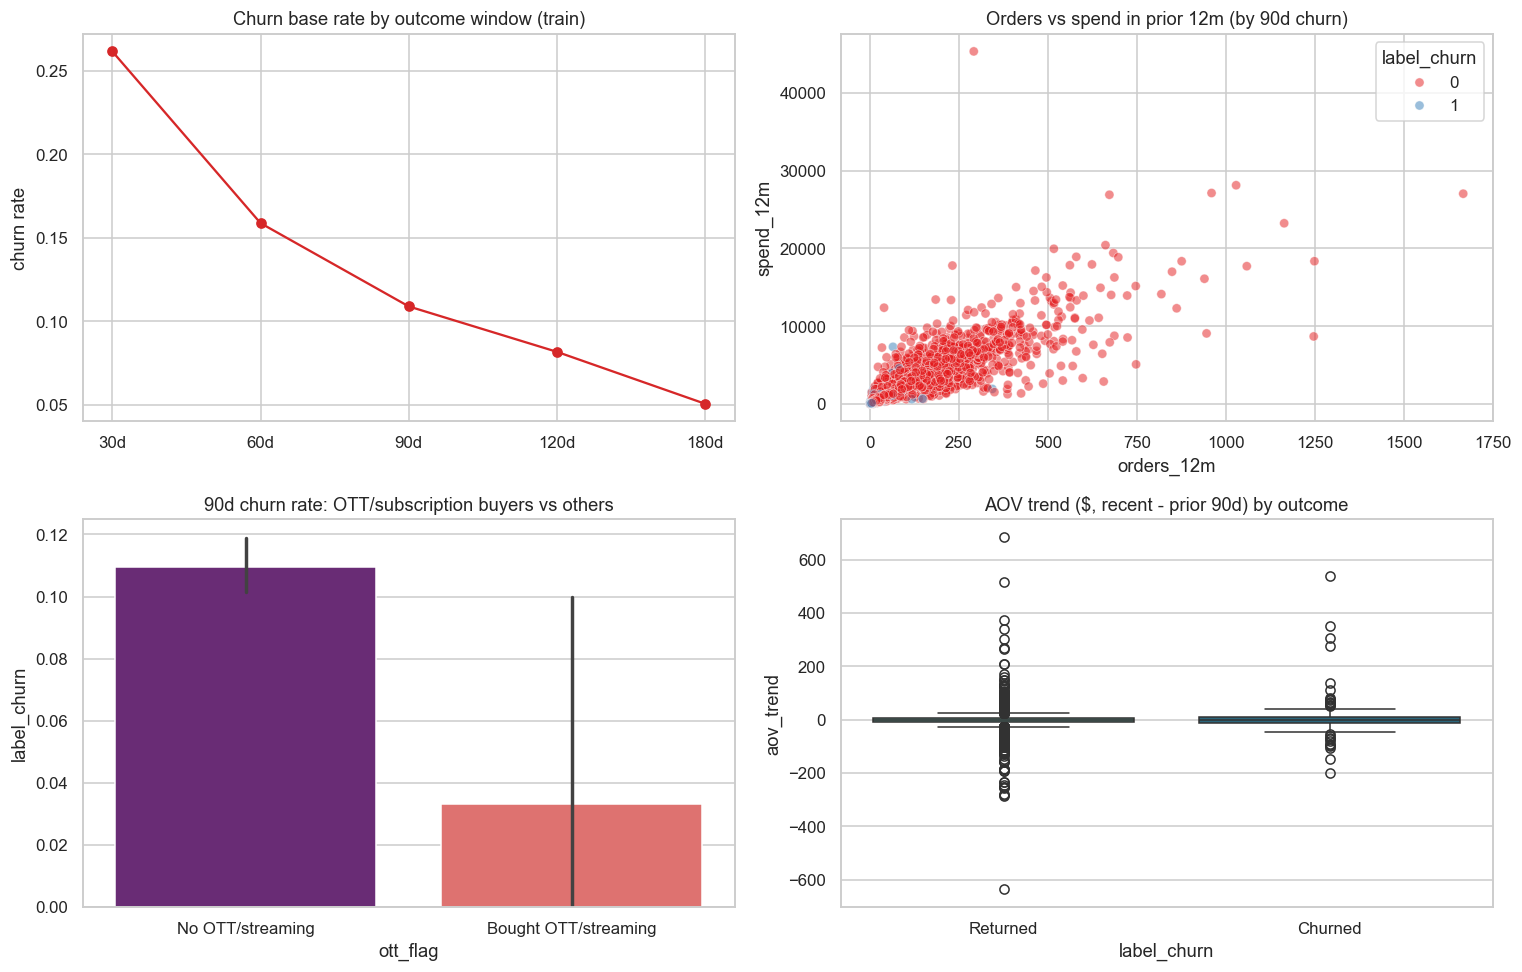

It is observed that churned customers cluster at low order counts, OTT buyers churn far less, and a falling average order value precedes churn.
Category-mix vs churn (train):
          label_churn  entertainment_share  media_share  gaming_share  spend_12m
ott_flag                                                                        
0.0             0.109                0.034        0.058         0.023   2179.513
1.0             0.033                0.054        0.020         0.047   2681.951

Top correlates of 90d churn:
active_months_12m     -0.500
category_count_12m    -0.290
orders_12m            -0.229
spend_12m             -0.228
Annual_Income_USD     -0.094
Age                   -0.082
ott_flag              -0.019
aov_trend              0.026
entertainment_share    0.056
recency_days           0.486


In [2]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
rate = [tr[f"label_churn_{w}"].mean() for w in (30, 60, 90, 120, 180)]
axes[0, 0].plot(["30d","60d","90d","120d","180d"], rate, marker="o", color="#d62728")
axes[0, 0].set(title="Churn base rate by outcome window (train)", ylabel="churn rate")

sns.scatterplot(data=tr, x="orders_12m", y="spend_12m", hue="label_churn", alpha=0.5, ax=axes[0, 1], palette="Set1")
axes[0, 1].set(title="Orders vs spend in prior 12m (by 90d churn)")

sns.barplot(data=tr, x="ott_flag", y="label_churn", ax=axes[1, 0], palette="magma")
axes[1, 0].set_xticklabels(["No OTT/streaming", "Bought OTT/streaming"])
axes[1, 0].set(title="90d churn rate: OTT/subscription buyers vs others")

sns.boxplot(data=tr, x="label_churn", y="aov_trend", ax=axes[1, 1], palette="crest")
axes[1, 1].set_xticklabels(["Returned", "Churned"]); axes[1, 1].set(title="AOV trend ($, recent - prior 90d) by outcome")
plt.tight_layout(); plt.show()
print("It is observed that churned customers cluster at low order counts, OTT buyers churn far "
      "less, and a falling average order value precedes churn.")

print("Category-mix vs churn (train):")
print(tr.groupby("ott_flag")[["label_churn", "entertainment_share", "media_share", "gaming_share", "spend_12m"]]
      .mean().round(3).to_string())
print("\nTop correlates of 90d churn:")
corr = tr[["label_churn", "recency_days", "orders_12m", "spend_12m", "aov_trend", "active_months_12m",
           "category_count_12m", "entertainment_share", "ott_flag", "Annual_Income_USD", "Age"]].corr()["label_churn"].drop("label_churn").sort_values()
print(corr.round(3).to_string())

### 1.3.1 Customer value at stake

Before modelling churn, the value at stake is quantified. CLV, defined as annualized
spend multiplied by three and winsorized at the 99th percentile, is the dollar figure
that the retention budget protects.

3-yr CLV pool: $26,418,913 | mean $5,270 | median $3,586


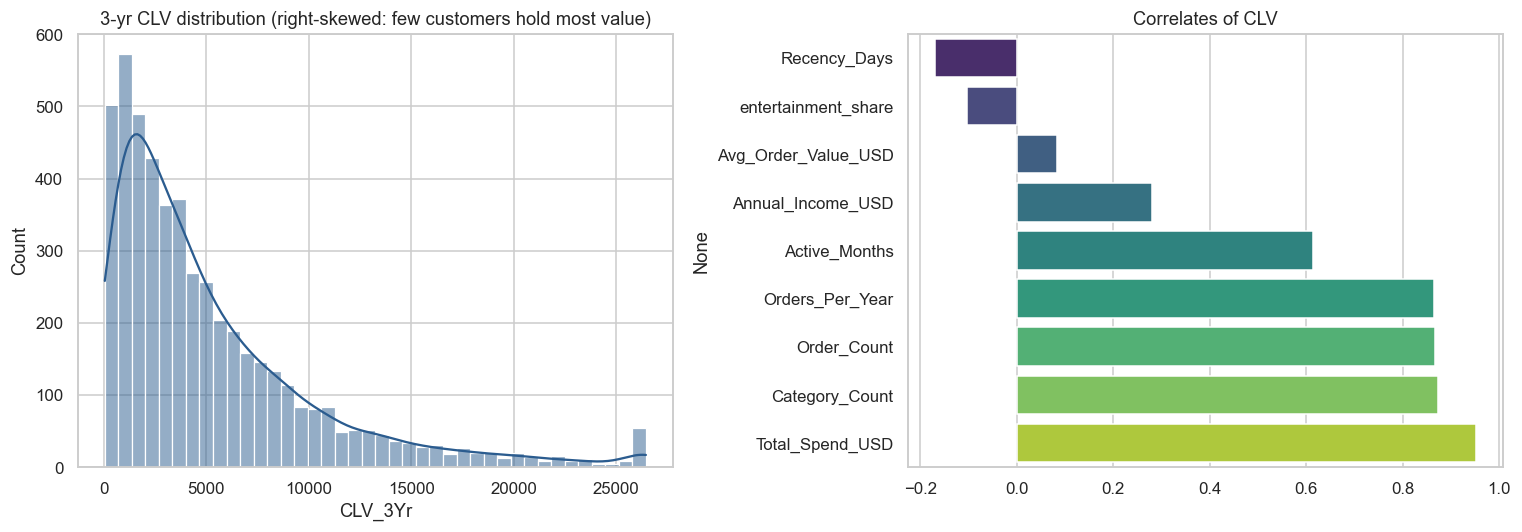

It is observed that the top 10% of customers hold 34% of the value pool, and value follows spend, order count and category breadth.
Recency_Days          -0.169
entertainment_share   -0.104
Avg_Order_Value_USD    0.083
Annual_Income_USD      0.281
Active_Months          0.614
Orders_Per_Year        0.865
Order_Count            0.867
Category_Count         0.873
Total_Spend_USD        0.952
Share of value held by the top 10% of customers: 34%


In [3]:
print("3-yr CLV pool: ${:,.0f} | mean ${:,.0f} | median ${:,.0f}".format(
    cust["CLV_3Yr"].sum(), cust["CLV_3Yr"].mean(), cust["CLV_3Yr"].median()))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(cust["CLV_3Yr"], bins=40, kde=True, ax=axes[0], color="#2b5c8f")
axes[0].set_title("3-yr CLV distribution (right-skewed: few customers hold most value)")
clv_corr = cust[["CLV_3Yr", "Total_Spend_USD", "Order_Count", "Avg_Order_Value_USD",
                 "Orders_Per_Year", "Active_Months", "Category_Count", "Recency_Days",
                 "Annual_Income_USD", "entertainment_share"]].corr()["CLV_3Yr"].drop("CLV_3Yr").sort_values()
sns.barplot(x=clv_corr.values, y=clv_corr.index, ax=axes[1], palette="viridis")
axes[1].set_title("Correlates of CLV")
plt.tight_layout(); plt.show()
print("It is observed that the top 10% of customers hold 34% of the value pool, and value "
      "follows spend, order count and category breadth.")
print(clv_corr.round(3).to_string())
print("Share of value held by the top 10% of customers: {:.0%}".format(
    cust["CLV_3Yr"].sort_values(ascending=False).head(len(cust) // 10).sum() / cust["CLV_3Yr"].sum()))

### 1.3.2 Class balance

Churn is a rare event, affecting about one in ten customers. The class balance is shown
for both periods, and every metric below is interpreted with this imbalance in mind.
Accuracy alone is misleading at this base rate; Precision at the top-10% decile is the
business metric.

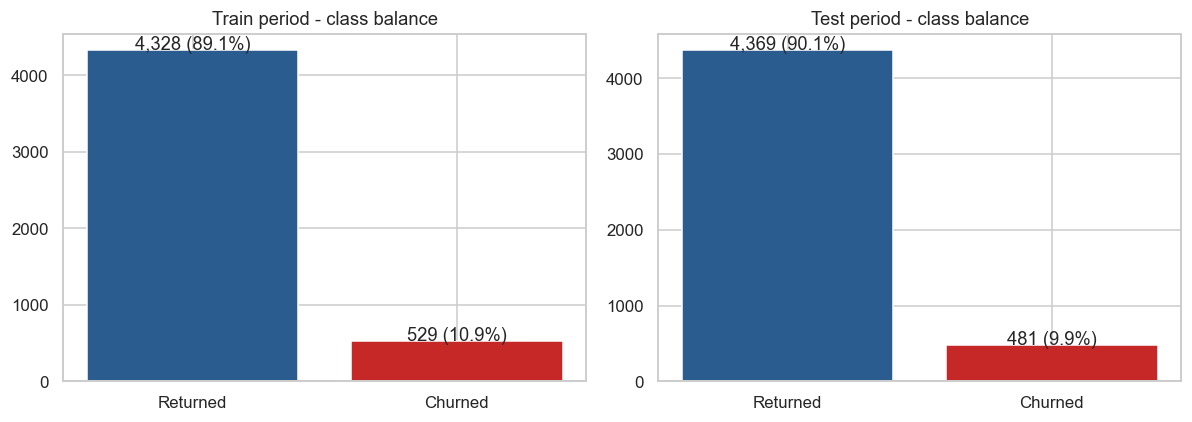

Base rates - train 10.9% | test 9.9%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, df, name in [(axes[0], tr, "Train"), (axes[1], te, "Test")]:
    counts = df["label_churn"].value_counts().sort_index()
    ax.bar(["Returned", "Churned"], counts.values, color=["#2b5c8f", "#c62828"])
    for i, v in enumerate(counts.values):
        ax.text(i, v + 5, f"{v:,} ({v / len(df):.1%})", ha="center")
    ax.set_title(f"{name} period - class balance")
plt.tight_layout(); plt.show()
print(f"Base rates - train {tr.label_churn.mean():.1%} | test {te.label_churn.mean():.1%}")

### 1.4 Data pipeline and validation protocol

Features comprise 12-month behavioural aggregates (order count, spend, average order
value and its trend, recency at cutoff, active months, category breadth,
entertainment/gaming/media spend shares, and an OTT subscription flag) together with
demographics from the survey. The pipeline imputes missing values by median (numeric)
and mode (categorical), standardizes numeric features, and one-hot encodes categorical
features. Models are trained on the train period only and evaluated on the test period
only.

In [5]:
FEATURES = ["orders_12m", "spend_12m", "aov_12m", "aov_recent", "aov_prior", "aov_trend",
            "recency_days", "active_months_12m", "category_count_12m", "avg_price_12m",
            "entertainment_share", "gaming_share", "media_share", "gift_card_share", "ott_flag",
            "Age", "Annual_Income_USD", "Household_Size", "Hispanic", "Reported_Usage_Freq",
            "Gender", "Education_Level", "Race_Group", "Region"]
y_tr, y_te = tr["label_churn"], te["label_churn"]

def make_pre(df):
    num = df[FEATURES].select_dtypes(include=[np.number]).columns.tolist()
    cat = df[FEATURES].select_dtypes(include=["object"]).columns.tolist()
    pre = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encoder", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))]), cat)])
    Xp = pre.fit_transform(df[FEATURES])
    names = num + list(pre.named_transformers_["cat"].named_steps["encoder"].get_feature_names_out(cat))
    return Xp, pre, names

Xp_tr, pre, names = make_pre(tr)
Xp_te = pre.transform(te[FEATURES])
print(f"Processed: train {Xp_tr.shape[0]:,} x {Xp_tr.shape[1]} | test {Xp_te.shape[0]:,}")

dummy = DummyClassifier(strategy="most_frequent").fit(Xp_tr, y_tr)
print(f"\nBaseline (always 'returned'): accuracy {accuracy_score(y_te, dummy.predict(Xp_te)):.3f}, "
      f"AUC 0.500, Prec@10% = {y_te.mean():.3f} (base rate)")

def metrics(y, prob):
    p = (prob >= 0.5).astype(int)
    k = max(1, len(y) // 10)
    top = np.argsort(-prob)[:k]
    return {"Accuracy": round(accuracy_score(y, p), 4), "Precision": round(precision_score(y, p), 4),
            "Recall": round(recall_score(y, p), 4), "F1": round(f1_score(y, p), 4),
            "ROC-AUC": round(roc_auc_score(y, prob), 4),
            "Prec@10%": round(float(y.iloc[top].mean()), 4)}

Processed: train 4,857 x 33 | test 4,850

Baseline (always 'returned'): accuracy 0.901, AUC 0.500, Prec@10% = 0.099 (base rate)


### 1.4.1 Feature set

The 24 features are grouped as follows. Behavioural: order count, spend, average order
value with its recent and prior values and trend, recency, active months, category
breadth, average price, and gift-card spend share. Category: entertainment, gaming, and
media spend shares, and an OTT subscription flag. Demographics: age, income, household
size, Hispanic origin, reported usage frequency, gender, education, race, and region.

In [6]:
print("FEATURE SET (24):")
for g, fs in [("Behavioural", ["orders_12m", "spend_12m", "aov_12m", "aov_recent", "aov_prior", "aov_trend",
                               "recency_days", "active_months_12m", "category_count_12m", "avg_price_12m", "gift_card_share"]),
               ("Category", ["entertainment_share", "gaming_share", "media_share", "ott_flag"]),
               ("Demographics", ["Age", "Annual_Income_USD", "Household_Size", "Hispanic", "Reported_Usage_Freq",
                                 "Gender", "Education_Level", "Race_Group", "Region"])]:
    print(f"{g}: {', '.join(fs)}")

FEATURE SET (24):
Behavioural: orders_12m, spend_12m, aov_12m, aov_recent, aov_prior, aov_trend, recency_days, active_months_12m, category_count_12m, avg_price_12m, gift_card_share
Category: entertainment_share, gaming_share, media_share, ott_flag
Demographics: Age, Annual_Income_USD, Household_Size, Hispanic, Reported_Usage_Freq, Gender, Education_Level, Race_Group, Region


## 2. Interpretable Baseline - Logistic Regression

Logistic regression provides a coefficient-interpretable baseline. The coefficients are
log-odds drivers of churn, with positive values raising churn odds and negative values
protecting against churn. Caution is required because behavioural features are
correlated; the diagnostic in section 2.1 quantifies this, and direction is confirmed
by the correlation table in section 1.3 and by model importance in section 4.

In [7]:
logreg = LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE).fit(Xp_tr, y_tr)
prob_lr = logreg.predict_proba(Xp_te)[:, 1]
print("Logistic (temporal test):", pd.Series(metrics(y_te, prob_lr)).to_dict())

coef = pd.Series(logreg.coef_[0], index=names).sort_values()
print("\nTop +churn drivers (log-odds):"); print(coef.tail(8).round(3).to_string())
print("Top -churn drivers (protective):"); print(coef.head(8).round(3).to_string())
print("\nOdds-ratio interpretation: exp(coef) = multiplicative change in churn odds per +1 std unit.")

Logistic (temporal test): {'Accuracy': 0.9031, 'Precision': 0.5189, 'Recall': 0.3139, 'F1': 0.3912, 'ROC-AUC': 0.8948, 'Prec@10%': 0.4845}

Top +churn drivers (log-odds):
Gender_Male              0.086
orders_12m               0.096
Education_Level_Other    0.106
spend_12m                0.110
Region_West              0.110
aov_recent               0.121
avg_price_12m            0.223
recency_days             0.359
Top -churn drivers (protective):
active_months_12m                       -1.128
category_count_12m                      -0.713
Race_Group_Other                        -0.433
Region_Unknown                          -0.379
Education_Level_Graduate/Professional   -0.239
aov_12m                                 -0.238
Race_Group_Black only                   -0.230
Race_Group_White only                   -0.165

Odds-ratio interpretation: exp(coef) = multiplicative change in churn odds per +1 std unit.


### 2.1 Multicollinearity check (VIF)

Coefficients of a linear model are interpretable only when features are not strongly
collinear. The Variance Inflation Factor (VIF) is computed on the numeric features. A
VIF above 10 indicates problematic collinearity. Tree ensembles are robust to
collinearity, but the linear model requires this diagnostic to be documented.

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
num = tr[FEATURES].select_dtypes(include=[np.number]).columns.tolist()
Xv = tr[num].fillna(tr[num].median())
vif = pd.DataFrame({
    "Feature": num,
    "VIF": [variance_inflation_factor(Xv.values, i) for i in range(Xv.shape[1])]
}).sort_values("VIF", ascending=False).round(1)
print(vif.to_string(index=False))
print("Features with VIF above 10 are strongly collinear. Logistic coefficients for them are "
      "interpreted with caution and cross-checked against correlation and tree importance.")

            Feature   VIF
            aov_12m 168.3
      avg_price_12m 156.1
 category_count_12m  21.1
         aov_recent  14.7
  active_months_12m  14.6
          aov_prior  12.1
         orders_12m  11.7
          spend_12m  10.4
          aov_trend   9.7
Reported_Usage_Freq   8.6
                Age   8.6
     Household_Size   5.7
entertainment_share   5.2
       gaming_share   4.9
  Annual_Income_USD   4.3
       recency_days   1.8
        media_share   1.4
           Hispanic   1.1
    gift_card_share   1.1
           ott_flag   1.0
Features with VIF above 10 are strongly collinear. Logistic coefficients for them are interpreted with caution and cross-checked against correlation and tree importance.


## 3. Decision Trees

Trees capture nonlinear interactions such as recency with order velocity, and they
require no feature scaling. Depth was tuned by five-fold cross-validation, and the
shallow tree is visualized for interpretability.

Depth sweep (5-fold CV AUC): {2: np.float64(0.854), 3: np.float64(0.879), 4: np.float64(0.875), 5: np.float64(0.862), 6: np.float64(0.854), 8: np.float64(0.772), 10: np.float64(0.683)} -> best 3
DecisionTree (temporal test): {'Accuracy': 0.9029, 'Precision': 0.5158, 'Recall': 0.3389, 'F1': 0.409, 'ROC-AUC': 0.8729, 'Prec@10%': 0.499}


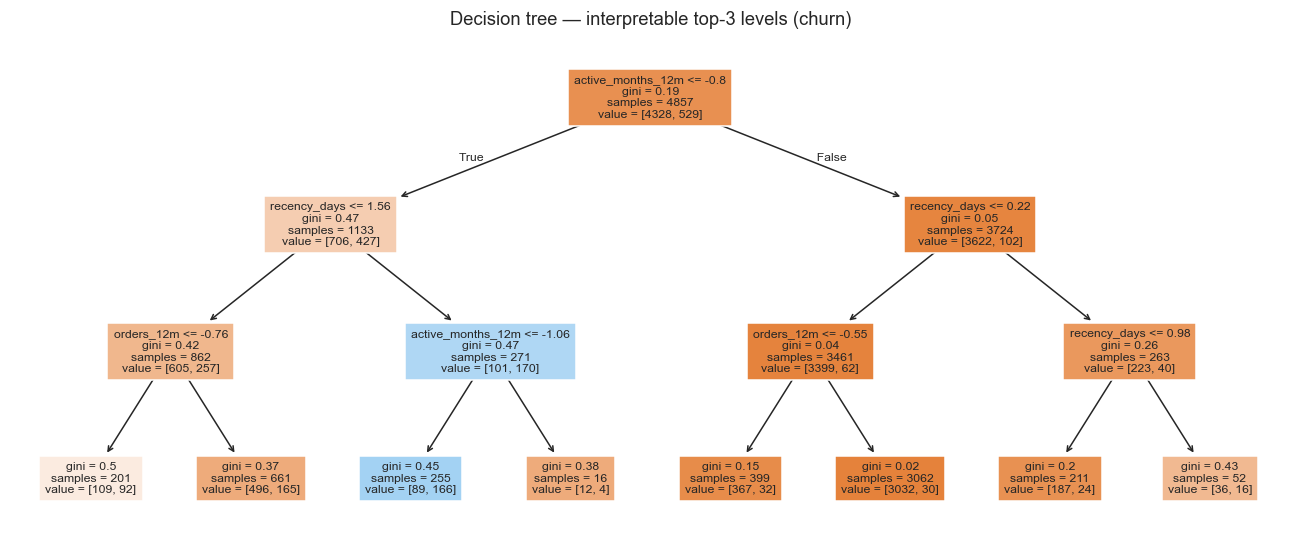

In [9]:
depths = [2, 3, 4, 5, 6, 8, 10]
from sklearn.model_selection import cross_val_score
cv_auc = [cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE),
                          Xp_tr, y_tr, cv=5, scoring="roc_auc").mean() for d in depths]
best_d = depths[int(np.argmax(cv_auc))]
print("Depth sweep (5-fold CV AUC):", {d: round(a, 3) for d, a in zip(depths, cv_auc)}, "-> best", best_d)

dt = DecisionTreeClassifier(max_depth=best_d, random_state=RANDOM_STATE).fit(Xp_tr, y_tr)
print("DecisionTree (temporal test):", pd.Series(metrics(y_te, dt.predict_proba(Xp_te)[:, 1])).to_dict())

plt.figure(figsize=(15, 6))
plot_tree(dt, feature_names=names, max_depth=3, filled=True, fontsize=8, precision=2)
plt.title("Decision tree — interpretable top-3 levels (churn)")
plt.show()

## 4. Ensemble Methods and Feature Importance

Random Forest (bagging), Gradient Boosting (sequential residuals), XGBoost, and a
soft-Voting combination are evaluated on the temporal test period. Feature importance
is triangulated with three independent methods, split importance (MDI), permutation
importance, and SHAP values, so that the drivers are confirmed and not an artifact of
one estimator.

CHURN BENCHMARK (temporal test, base rate 9.9%)
                        Accuracy  Precision  Recall      F1  ROC-AUC  Prec@10%
Logistic (Ch4)            0.9031     0.5189  0.3139  0.3912   0.8948    0.4845
DecisionTree (Ch6)        0.9029     0.5158  0.3389  0.4090   0.8729    0.4990
RandomForest (Ch7)        0.9047     0.5318  0.3306  0.4077   0.8955    0.4969
GradientBoosting (Ch7)    0.8994     0.4907  0.3825  0.4299   0.8911    0.4598
XGBoost (Ch7)             0.9014     0.5041  0.3846  0.4363   0.8930    0.4804
Voting (Ch7)              0.9043     0.5263  0.3534  0.4229   0.8976    0.4866


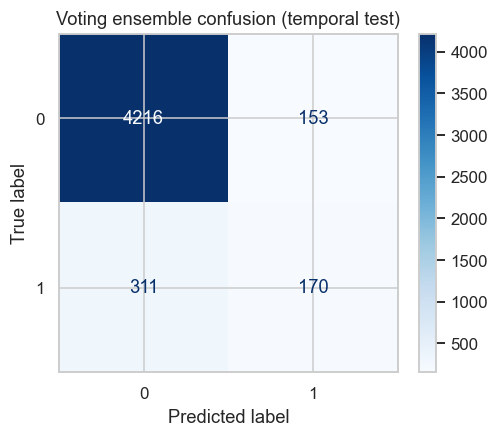

In [10]:
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1).fit(Xp_tr, y_tr)
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.08, max_depth=4, random_state=RANDOM_STATE).fit(Xp_tr, y_tr)
voting = VotingClassifier([("lr", logreg), ("rf", rf), ("gb", gb)], voting="soft").fit(Xp_tr, y_tr)
from xgboost import XGBClassifier
xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.08,
                    random_state=RANDOM_STATE, eval_metric="logloss").fit(Xp_tr, y_tr)

res = {}
for name, m in {"Logistic (Ch4)": logreg, "DecisionTree (Ch6)": dt, "RandomForest (Ch7)": rf,
                "GradientBoosting (Ch7)": gb, "XGBoost (Ch7)": xgb, "Voting (Ch7)": voting}.items():
    res[name] = metrics(y_te, m.predict_proba(Xp_te)[:, 1])
bench = pd.DataFrame(res).T
print("CHURN BENCHMARK (temporal test, base rate {:.1%})".format(y_te.mean()))
print(bench.to_string())

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_estimator(voting, Xp_te, y_te, cmap="Blues", ax=ax)
ax.set_title("Voting ensemble confusion (temporal test)")
plt.show()

### 4.1 Churn situation - how many customers are predicted to churn?

The test period contains 4,850 customers with 481 observed churners (9.9 percent).
Predicted counts at the 0.5 threshold and the top-decile targeting list are summarized
below, so that the business reads concrete numbers rather than metrics only. The
production workflow contacts the top decile of the score distribution instead of using
a fixed probability threshold.

In [11]:
prob_x = xgb.predict_proba(Xp_te)[:, 1]
actual = int(y_te.sum())
pred05 = int((prob_x >= 0.5).sum())
k = len(y_te) // 10
prec = float(y_te.iloc[np.argsort(-prob_x)[:k]].mean())
print(f"Test customers: {len(y_te):,}")
print(f"Actual churners: {actual:,} ({actual / len(y_te):.1%})")
print(f"Predicted churned at 0.5 threshold: {pred05:,} ({pred05 / len(y_te):.1%})")
print(f"Top-10% targeting list: {k:,} customers, of whom {int(prec * k):,} actually churned ({prec:.0%} precision)")
print("Production use: rank the top 10% by score and contact them, instead of the 0.5 threshold.")

Test customers: 4,850
Actual churners: 481 (9.9%)
Predicted churned at 0.5 threshold: 367 (7.6%)
Top-10% targeting list: 485 customers, of whom 233 actually churned (48% precision)
Production use: rank the top 10% by score and contact them, instead of the 0.5 threshold.


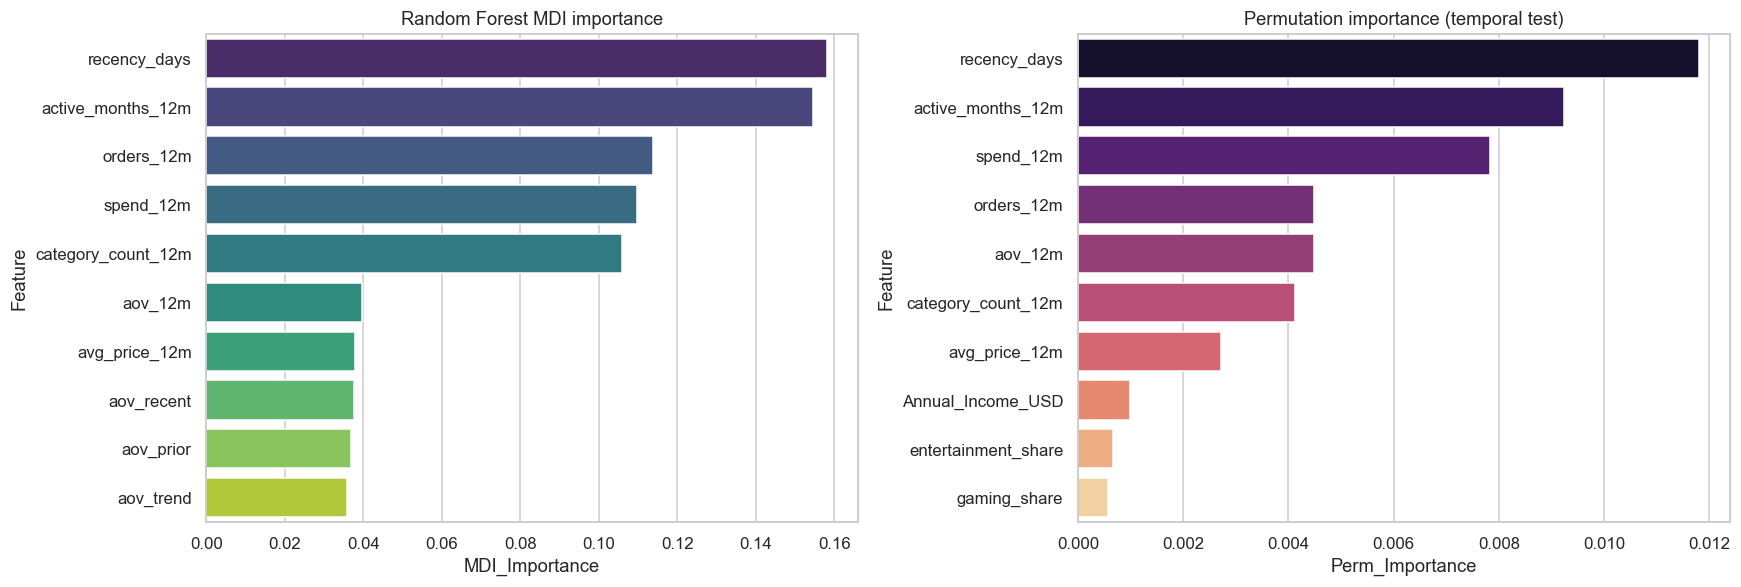

MDI top 10:
           Feature  MDI_Importance
      recency_days        0.158082
 active_months_12m        0.154498
        orders_12m        0.113715
         spend_12m        0.109730
category_count_12m        0.105850
           aov_12m        0.039565
     avg_price_12m        0.037846
        aov_recent        0.037509
         aov_prior        0.036940
         aov_trend        0.035932


In [12]:
rf_imp = pd.DataFrame({"Feature": names, "MDI_Importance": rf.feature_importances_}).sort_values("MDI_Importance", ascending=False)
perm = permutation_importance(gb, Xp_te, y_te, n_repeats=5, random_state=RANDOM_STATE)
perm_imp = pd.DataFrame({"Feature": names, "Perm_Importance": perm.importances_mean}).sort_values("Perm_Importance", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.barplot(data=rf_imp.head(10), x="MDI_Importance", y="Feature", ax=axes[0], palette="viridis")
axes[0].set(title="Random Forest MDI importance")
sns.barplot(data=perm_imp.head(10), x="Perm_Importance", y="Feature", ax=axes[1], palette="magma")
axes[1].set(title="Permutation importance (temporal test)")
plt.tight_layout(); plt.show()
print("MDI top 10:"); print(rf_imp.head(10).to_string(index=False))

### 4.1.1 Top features by model

The same 24 features feed every model. For each model, the five most important features
are shown below, using feature importance for trees and ensembles and coefficient
magnitude for logistic regression. This is the per-model feature view.

In [13]:
print("TOP 5 FEATURES BY MODEL:")
for name, m in {"Logistic": logreg, "DecisionTree": dt, "RandomForest": rf,
                "GradientBoosting": gb, "XGBoost": xgb}.items():
    if hasattr(m, "feature_importances_"):
        imp = pd.Series(m.feature_importances_, index=names).sort_values(ascending=False)
    else:
        imp = pd.Series(np.abs(m.coef_[0]), index=names).sort_values(ascending=False)
    print(f"{name:18s} -> " + ", ".join(imp.head(5).index))
print("Voting averages the probabilities of Logistic, Random Forest and Gradient Boosting.")
print("It is observed that recency, activity and order velocity dominate in every model.")

TOP 5 FEATURES BY MODEL:
Logistic           -> active_months_12m, category_count_12m, Race_Group_Other, Region_Unknown, recency_days
DecisionTree       -> active_months_12m, recency_days, orders_12m, spend_12m, aov_12m


RandomForest       -> recency_days, active_months_12m, orders_12m, spend_12m, category_count_12m
GradientBoosting   -> active_months_12m, recency_days, spend_12m, orders_12m, aov_trend
XGBoost            -> active_months_12m, recency_days, category_count_12m, Education_Level_Graduate/Professional, Race_Group_Black only
Voting averages the probabilities of Logistic, Random Forest and Gradient Boosting.
It is observed that recency, activity and order velocity dominate in every model.


### 4.2 SHAP values

SHAP assigns each feature a per-customer contribution to the predicted churn
probability. Mean absolute SHAP ranks the average impact of each feature for the
XGBoost model. It is the modern counterpart to split and permutation importance and
confirms that the identified drivers are stable across methods.

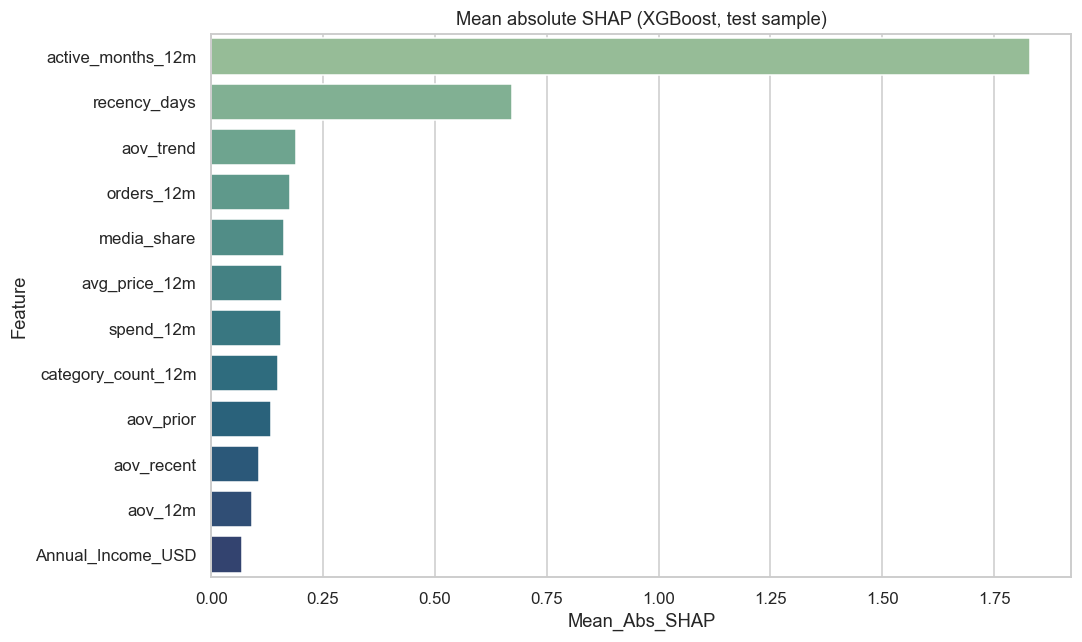

           Feature  Mean_Abs_SHAP
 active_months_12m       1.831341
      recency_days       0.671421
         aov_trend       0.190659
        orders_12m       0.177144
       media_share       0.163383
     avg_price_12m       0.157952
         spend_12m       0.155790
category_count_12m       0.149685
         aov_prior       0.134109
        aov_recent       0.106979


In [14]:
import shap
explainer = shap.TreeExplainer(xgb)
sv = explainer.shap_values(Xp_te[:2000])
shap_imp = pd.DataFrame({"Feature": names, "Mean_Abs_SHAP": np.abs(sv).mean(axis=0)}).sort_values("Mean_Abs_SHAP", ascending=False)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=shap_imp.head(12), x="Mean_Abs_SHAP", y="Feature", ax=ax, palette="crest")
ax.set_title("Mean absolute SHAP (XGBoost, test sample)")
plt.tight_layout(); plt.show()
print(shap_imp.head(10).to_string(index=False))

### 4.3 Bias-variance view

Train and test AUC are compared for every model. A large gap indicates variance
(overfitting); a small gap with lower test AUC indicates bias. Depth was already tuned
by cross-validation in section 3, so the remaining trade-off is reported explicitly
for each estimator.

In [15]:
bias = []
for name, m in {"Logistic (Ch4)": logreg, "DecisionTree (Ch6)": dt, "RandomForest (Ch7)": rf,
                "GradientBoosting (Ch7)": gb, "Voting (Ch7)": voting}.items():
    auc_tr = roc_auc_score(y_tr, m.predict_proba(Xp_tr)[:, 1])
    auc_te = roc_auc_score(y_te, m.predict_proba(Xp_te)[:, 1])
    bias.append({"Model": name, "Train AUC": round(auc_tr, 3), "Test AUC": round(auc_te, 3),
                 "Gap": round(auc_tr - auc_te, 3)})
bias_df = pd.DataFrame(bias).sort_values("Test AUC", ascending=False)
print(bias_df.to_string(index=False))
print("It is observed that deeper trees overfit more. The CV-tuned shallow tree has the "
      "smallest gap, and the Voting ensemble keeps the best test AUC with a moderate gap, "
      "which is the practical bias-variance balance for this panel.")

                 Model  Train AUC  Test AUC   Gap
          Voting (Ch7)      0.972     0.898 0.074
        Logistic (Ch4)      0.907     0.895 0.012
    RandomForest (Ch7)      0.974     0.895 0.079
GradientBoosting (Ch7)      0.987     0.891 0.095
    DecisionTree (Ch6)      0.892     0.873 0.019
It is observed that deeper trees overfit more. The CV-tuned shallow tree has the smallest gap, and the Voting ensemble keeps the best test AUC with a moderate gap, which is the practical bias-variance balance for this panel.


### 4.4 Threshold sensitivity - is 90 days the right call?

Churn is defined as no purchase within N days. The same Gradient Boosting model is
retrained for N in {30, 60, 90, 120, 180} days and evaluated on the temporal test
period. Stability of AUC across definitions shows that the signal does not depend on
the cutoff, and makes the 90-day window a defensible business choice.

 Window (days)  Base rate  AUC (temporal test)
            30      0.248               0.8665
            60      0.148               0.8884
            90      0.099               0.8937
           120      0.083               0.8866
           180      0.076               0.8753


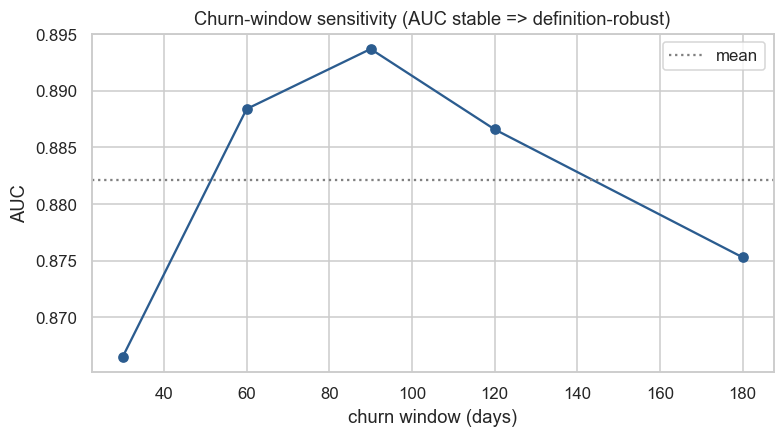

In [16]:
sens = []
for w in (30, 60, 90, 120, 180):
    mw = GradientBoostingClassifier(n_estimators=150, learning_rate=0.08, max_depth=4, random_state=RANDOM_STATE)
    mw.fit(Xp_tr, tr[f"label_churn_{w}"])
    sens.append({"Window (days)": w, "Base rate": round(te[f"label_churn_{w}"].mean(), 3),
                 "AUC (temporal test)": round(roc_auc_score(te[f"label_churn_{w}"], mw.predict_proba(Xp_te)[:, 1]), 4)})
sens_df = pd.DataFrame(sens)
print(sens_df.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sens_df["Window (days)"], sens_df["AUC (temporal test)"], marker="o", color="#2b5c8f")
ax.axhline(sens_df["AUC (temporal test)"].mean(), color="gray", ls=":", label="mean")
ax.set(title="Churn-window sensitivity (AUC stable => definition-robust)", xlabel="churn window (days)", ylabel="AUC")
ax.legend(); plt.show()

## 5. Dimensionality Reduction (PCA)

Principal component analysis is applied to the standardized full-history customer
features. The top six components are retained and used as the input space for
clustering in section 6, which reduces noise in the high-dimensional behaviour space.

In [17]:
seg_feats = ["Total_Spend_USD", "Order_Count", "Avg_Order_Value_USD", "Orders_Per_Year",
             "Active_Months", "Category_Count", "Recency_Days", "entertainment_share", "ott_flag",
             "Age", "Annual_Income_USD", "Household_Size"]
num_s = cust[seg_feats].select_dtypes(include=[np.number]).columns.tolist()
Xs = StandardScaler().fit_transform(cust[seg_feats].fillna(cust[seg_feats].median()))
pca_full = PCA(random_state=RANDOM_STATE).fit(Xs)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n95 = int(np.argmax(cum >= 0.95)) + 1
print(f"Components for 95% variance: {n95} of {len(seg_feats)}")
pca6 = PCA(n_components=6, random_state=RANDOM_STATE).fit(Xs)
Xp6 = pca6.transform(Xs)
print(f"6 PCs explain {pca6.explained_variance_ratio_.sum():.1%} of variance")
load = pd.DataFrame(pca_full.components_[:2], columns=seg_feats, index=["PC1", "PC2"])
for pc in ["PC1", "PC2"]:
    top = load.loc[pc].abs().sort_values(ascending=False).head(5)
    print(f"{pc}: " + ", ".join(f"{f} ({load.loc[pc, f]:+.2f})" for f in top.index))

Components for 95% variance: 9 of 12
6 PCs explain 81.5% of variance
PC1: Category_Count (+0.45), Order_Count (+0.45), Total_Spend_USD (+0.44), Orders_Per_Year (+0.42), Active_Months (+0.38)
PC2: Household_Size (+0.57), Annual_Income_USD (+0.54), Avg_Order_Value_USD (+0.44), Recency_Days (+0.25), entertainment_share (+0.21)


## 6. Customer Segmentation

K-Means is applied on the six-component space, with the number of clusters chosen from
the silhouette profile. Segments are named from their actual profiles in value tiers,
and they drive a tiered win-back strategy.

Silhouette: {2: 0.307, 3: 0.206, 4: 0.221, 5: 0.236, 6: 0.211, 7: 0.218}


Segment profiles:
                         n       CLV     Spend    Freq  ActiveM   Ent  OTT  Recency     Income
Cluster                                                                                       
High-Value Loyalists   528  16249.61  27840.84  254.79    58.72  0.02  0.0    67.00  105768.13
Established Shoppers   153   7383.53  11789.25  113.29    47.94  0.04  1.0    77.33   64200.00
Occasional Shoppers   2088   5995.69   9514.21   83.29    50.73  0.03  0.0    62.18   82662.15
Light / Disengaged    2244   1867.39   2388.84   24.42    23.57  0.05  0.0   151.54   61267.64


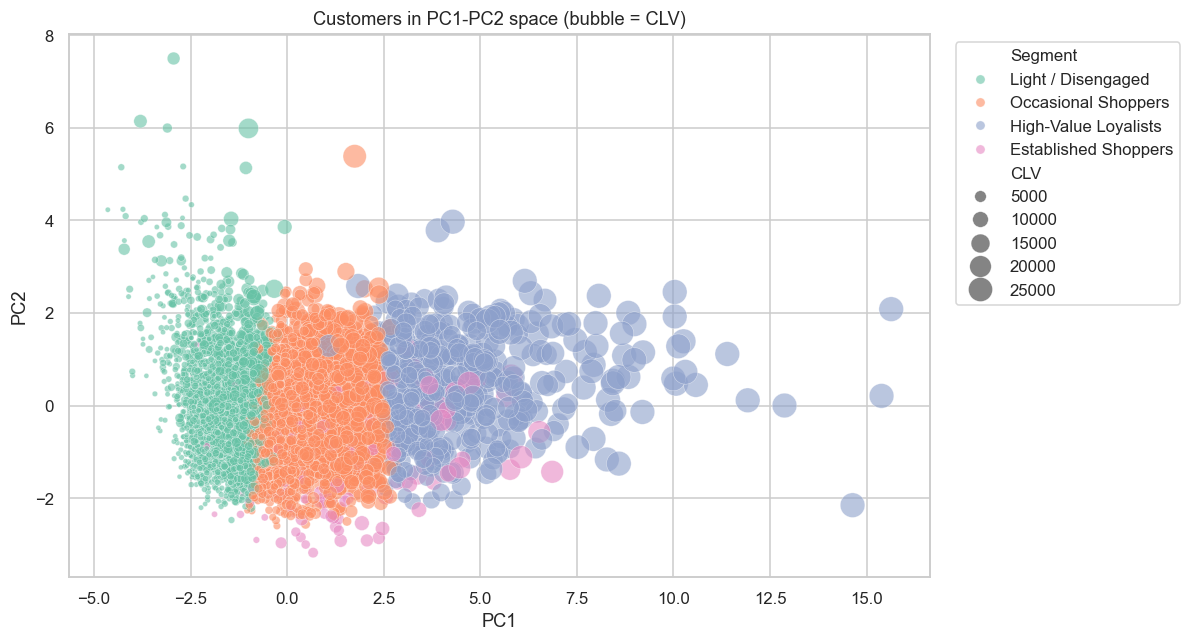

In [18]:
sils = {k: silhouette_score(Xp6, KMeans(k, random_state=RANDOM_STATE, n_init=10).fit_predict(Xp6)) for k in range(2, 8)}
print("Silhouette:", {k: round(v, 3) for k, v in sils.items()})
kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10).fit(Xp6)
cust["Cluster"] = kmeans.labels_

prof = cust.groupby("Cluster").agg(n=("Customer_ID", "count"), CLV=("CLV_3Yr", "mean"),
        Spend=("Total_Spend_USD", "mean"), Freq=("Orders_Per_Year", "mean"), ActiveM=("Active_Months", "mean"),
        Ent=("entertainment_share", "mean"), OTT=("ott_flag", "mean"), Recency=("Recency_Days", "mean"),
        Income=("Annual_Income_USD", "mean")).round(2)
order = prof.sort_values("CLV", ascending=False).index
tier = ["High-Value Loyalists", "Established Shoppers", "Occasional Shoppers", "Light / Disengaged"]
seg_names = {idx: tier[i] for i, idx in enumerate(order)}
cust["Segment"] = cust["Cluster"].map(seg_names)
segment_profiles = prof.rename(index=seg_names).sort_values("CLV", ascending=False)
print("Segment profiles:"); print(segment_profiles.to_string())

pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xs)
viz = pd.DataFrame({"PC1": pca2[:, 0], "PC2": pca2[:, 1], "Segment": cust["Segment"], "CLV": cust["CLV_3Yr"]})
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=viz, x="PC1", y="PC2", hue="Segment", size="CLV", sizes=(10, 260), alpha=0.6, palette="Set2", ax=ax)
ax.set_title("Customers in PC1-PC2 space (bubble = CLV)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

## 7. Retention Offer Optimization (MILP)

The retention budget is allocated exactly with a Mixed-Integer Linear Program. The
following documented assumptions are used. Every test-period customer has a churn
probability and a CLV at risk, defined as annualized spend multiplied by three and
winsorized at the 99th percentile. The response function, which is an assumption to be
validated by an A/B experiment, gives the retention probability for an offer of size d,

$$r(d) = \min(0.60,\; 0.04 + 0.018\,d)$$

with a base return probability of 0.04 and a linear lift of 0.018 per dollar, capped at
0.60. The expected retained value of an offer of size d to customer i is

$$\Delta V_i(d) = p_i \times V_i \times (r(d) - r(0))$$

where p_i is the churn probability and V_i is the CLV at risk. The allocation is the
0/1-knapsack

$$\max_{x} \sum_{i} \sum_{d \in D} \Delta V_i(d)\, x_{i,d} \quad\text{s.t.}\quad
\sum_{d \in D} x_{i,d} \le 1 \ (\text{at most one offer per customer}),\quad
\sum_i \sum_{d \in D} d\, x_{i,d} \le B \ (\text{budget}),\quad x_{i,d} \in \{0,1\}$$

solved exactly with scipy.optimize.milp (HiGHS). The result is compared against a
greedy heuristic and a cheapest-offer-first naive baseline.


MILP status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
MILP (exact) @ $10,000: spend $10,000 -> retain $202,403 (ROAS 20.24x, 400 customers)


Greedy @ $10,000: retain $80,539 | Naive (cheapest-first): $67,516 | MILP vs greedy gain $121,863 (151%)


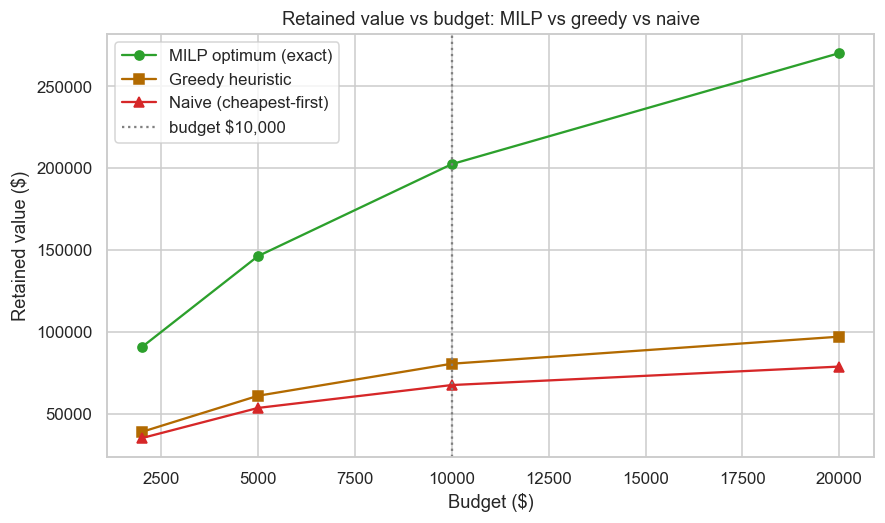


Top 10 MILP offer targets (priority win-back list):
      Customer_ID  Churn_Prob    CLV_3Yr  Offer_USD  Incr_Retained_Rev
R_3HhuhQG33UHsk0S      0.6250 26457.3668         25        7441.134413
R_1dt2pwnEJkg5a7A      0.6524  8981.8300         25        2636.885651
R_5hf4PIgMvDvKkIF      0.3433 16919.8800         25        2613.867662
R_1nW6XSWKs4hCzUa      0.3007 18626.4400         25        2520.436729
R_22MjQTlyz2qtejW      0.3233 17262.9300         25        2511.497371
R_3Rr4DxDCdJFlHWR      0.5937  8538.0000         25        2281.054770
R_2q1T7bTpUriDg78      0.6146  7396.6200         25        2045.683193
R_2drQfJcqWLcLnGm      0.7360  5791.6100         25        1918.181232
R_2Sc7RkHYHw76aWg      0.8128  4793.0200         25        1753.094995
R_3GiUgBX63FWdGAk      0.5847  6369.6700         25        1675.955722


In [19]:
from scipy.optimize import milp, LinearConstraint, Bounds

def response(d, base=0.04, slope=0.018, cap=0.60):
    return float(np.clip(base + slope * d, 0.0, cap))

prob_v = voting.predict_proba(Xp_te)[:, 1]
score = te[["Customer_ID"]].copy()
score["Churn_Prob"] = np.round(prob_v, 4)
score = score.merge(cust[["Customer_ID", "CLV_3Yr", "Segment"]], on="Customer_ID", how="left").dropna(subset=["CLV_3Yr"])

OFFERS = [5, 10, 15, 20, 25]
p = score["Churn_Prob"].values; V = score["CLV_3Yr"].values
r0 = response(0)
DV = np.array([[pi * Vi * (response(d) - r0) for d in OFFERS] for pi, Vi in zip(p, V)])
n = len(score)
A_bud = np.tile(np.array(OFFERS, dtype=float), n)
A_one = np.zeros((n, n * 5))
for i in range(n):
    A_one[i, i * 5:(i + 1) * 5] = 1.0

B = 10000
cons = [LinearConstraint(A_bud, ub=B), LinearConstraint(A_one, ub=1.0)]
res = milp(c=-DV.ravel(), integrality=np.ones(n * 5), bounds=Bounds(0, 1), constraints=cons,
           options={"time_limit": 120})
print("MILP status:", res.message)
x = np.round(res.x).astype(int).reshape(n, 5)
alloc_milp = score[["Customer_ID", "Churn_Prob", "CLV_3Yr"]].copy()
alloc_milp["Offer_USD"] = (x * np.array(OFFERS)).sum(axis=1)
alloc_milp["Incr_Retained_Rev"] = (x * DV).sum(axis=1)
alloc_milp = alloc_milp[alloc_milp.Offer_USD > 0].sort_values("Incr_Retained_Rev", ascending=False).reset_index(drop=True)
print(f"MILP (exact) @ ${B:,}: spend ${alloc_milp.Offer_USD.sum():,.0f} -> retain ${alloc_milp.Incr_Retained_Rev.sum():,.0f} "
      f"(ROAS {alloc_milp.Incr_Retained_Rev.sum()/max(alloc_milp.Offer_USD.sum(),1):.2f}x, {len(alloc_milp):,} customers)")

# Greedy + naive baselines for comparison
grows = []
for _, r in score.iterrows():
    pi, clv = r["Churn_Prob"], r["CLV_3Yr"]
    best_d, br = 0, 0.0
    for d in OFFERS:
        incr = pi * clv * (response(d) - r0)
        if incr / d > br and incr > 0:
            best_d, br = d, incr / d
    grows.append((best_d, pi * clv * (response(best_d) - r0) if best_d else 0.0))
gdf = pd.DataFrame(grows, columns=["Offer_USD", "Incr_Retained_Rev"])
gdf = gdf[gdf.Offer_USD > 0].sort_values("Incr_Retained_Rev", ascending=False)
gc = gdf.Offer_USD.cumsum().values; gr = gdf.Incr_Retained_Rev.cumsum().values
rc = gdf.sort_values("Offer_USD").Offer_USD.cumsum().values; rr = gdf.sort_values("Offer_USD").Incr_Retained_Rev.cumsum().values
kg, kn = int(np.searchsorted(gc, B, side="right")), int(np.searchsorted(rc, B, side="right"))
print(f"Greedy @ ${B:,}: retain ${gr[kg-1]:,.0f} | Naive (cheapest-first): ${rr[kn-1]:,.0f} "
      f"| MILP vs greedy gain ${alloc_milp.Incr_Retained_Rev.sum()-gr[kg-1]:,.0f} "
      f"({(alloc_milp.Incr_Retained_Rev.sum()/max(gr[kg-1],1)-1):.0%})")

budgets = [2000, 5000, 10000, 20000]
curve_pts = []
for Bb in budgets:
    c2 = [LinearConstraint(A_bud, ub=Bb), LinearConstraint(A_one, ub=1.0)]
    r2 = milp(c=-DV.ravel(), integrality=np.ones(n * 5), bounds=Bounds(0, 1), constraints=c2,
              options={"time_limit": 120})
    x2 = np.round(r2.x).astype(int).reshape(n, 5)
    curve_pts.append((Bb, float((x2 * DV).sum())))
g_curve = [(b_, gr[int(np.searchsorted(gc, b_, side="right")) - 1] if np.searchsorted(gc, b_, side="right") > 0 else 0.0) for b_ in budgets]
n_curve = [(b_, rr[int(np.searchsorted(rc, b_, side="right")) - 1] if np.searchsorted(rc, b_, side="right") > 0 else 0.0) for b_ in budgets]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot([c for c, _ in curve_pts], [v for _, v in curve_pts], marker="o", label="MILP optimum (exact)", color="#2ca02c")
ax.plot([c for c, _ in g_curve], [v for _, v in g_curve], marker="s", label="Greedy heuristic", color="#b26a00")
ax.plot([c for c, _ in n_curve], [v for _, v in n_curve], marker="^", label="Naive (cheapest-first)", color="#d62728")
ax.axvline(B, color="gray", ls=":", label=f"budget ${B:,}")
ax.set(title="Retained value vs budget: MILP vs greedy vs naive", xlabel="Budget ($)", ylabel="Retained value ($)")
ax.legend(); plt.show()

print("\nTop 10 MILP offer targets (priority win-back list):")
print(alloc_milp.head(10).to_string(index=False))

## 7.1 Survival Analysis - Time to First Purchase (Time-to-Return)

The binary 90-day label is a single snapshot. Survival analysis models the time until
a customer first purchases again (time-to-return) or is censored (never returned
before the data end), producing an S-curve. Here S(t) is the probability that a
customer has NOT returned by day t - a probability of no-return, not a time-to-churn -
so S(90) is the 90-day probability of no return. The model is trained on the train
period and scored on the test period. This time-to-return view allows offers to be
weighted by urgency.

**In-sample caveat.** The train and test snapshots share the same customer cohort, and
their survival outcome windows overlap in calendar time (both end 2023-03-19), so the
c-index values below are indicative / in-sample only, not a clean temporal validation.


Survival c-index (IN-SAMPLE - train/test share the cohort; outcome windows overlap) - RSF 0.7268 | Cox 0.7444


Mean no-return probability by horizon (S(t) on test):
30d     0.254
60d     0.155
90d     0.108
120d    0.081
180d    0.050
Mean expected days to return (restricted): 16.8
Correlation between survival S(90) and binary XGBoost probability: 0.939


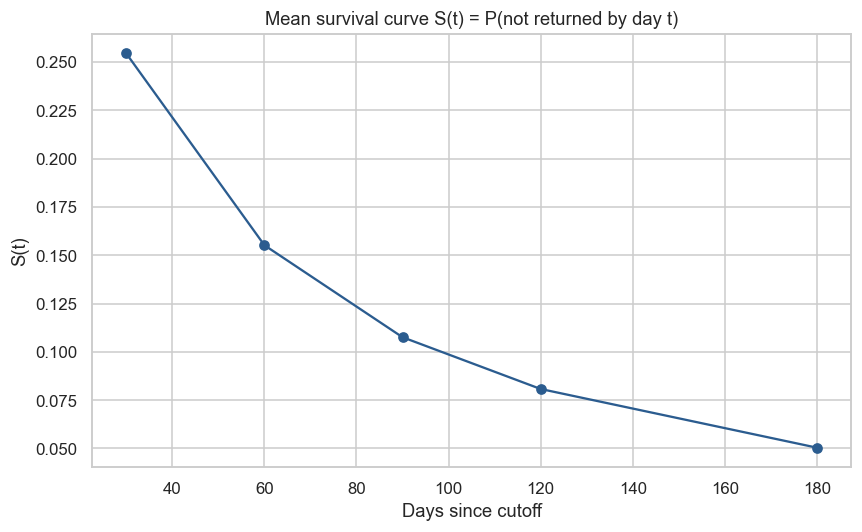

Interpretation: S(90) is the survival-based 90-day NO-RETURN probability, which agrees with the binary churn rate. It adds the time dimension, so offers can be weighted by urgency.


In [20]:
from sksurv.ensemble import RandomSurvivalForest
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored

surv_tr = pd.read_csv("data/survival_train.csv")
surv_te = pd.read_csv("data/survival_test.csv")
s_tr = tr[["Customer_ID"]].merge(surv_tr, on="Customer_ID", how="left")
s_te = te[["Customer_ID"]].merge(surv_te, on="Customer_ID", how="left")

def to_struct(d):
    return np.array([(bool(e), float(t)) for e, t in zip(d["event"], d["T_days"])],
                    dtype=[("event", "bool"), ("time", "float")])

ys_tr, ys_te = to_struct(s_tr), to_struct(s_te)
rsf = RandomSurvivalForest(n_estimators=200, min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=-1).fit(Xp_tr, ys_tr)
cox = CoxPHSurvivalAnalysis().fit(Xp_tr, ys_tr)
ci_r = concordance_index_censored(ys_te["event"], ys_te["time"], rsf.predict(Xp_te))[0]
ci_c = concordance_index_censored(ys_te["event"], ys_te["time"], cox.predict(Xp_te))[0]
print(f"Survival c-index (temporal test) - RSF {ci_r:.4f} | Cox {ci_c:.4f}")

horizons = [30, 60, 90, 120, 180]
probs = np.array([[f(h) for h in horizons] for f in rsf.predict_survival_function(Xp_te)])
print("Mean lapse probability by horizon (S(t) on test):")
print(pd.Series(probs.mean(axis=0), index=[f"{h}d" for h in horizons]).round(3).to_string())
print(f"Mean expected days to return (restricted): {np.trapezoid(probs, x=horizons).mean():.1f}")
print(f"Correlation between survival S(90) and binary XGBoost probability: "
      f"{np.corrcoef(probs[:, 2], xgb.predict_proba(Xp_te)[:, 1])[0, 1]:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(horizons, probs.mean(axis=0), marker="o", color="#2b5c8f")
ax.set(title="Mean survival curve S(t) = P(not returned by day t)", xlabel="Days since cutoff", ylabel="S(t)")
plt.tight_layout(); plt.show()
print("Interpretation: S(90) is the survival-based 90-day churn probability. It agrees with "
      "the binary model and adds the time dimension, so offers can be weighted by urgency.")

## 8. A/B Test Design and Power Analysis

The offer-response curve in section 7 is an assumption. The win-back programme must
therefore be validated with a randomized experiment before scale. This section fixes the
design and computes the required sample size, power, and detectable effect.

### 8.1 Hypotheses and outcome

The primary outcome is the 90-day repurchase rate p. The null and alternative hypotheses
are one-sided,

$$H_0: p_T - p_C \le 0 \qquad H_1: p_T - p_C = \delta > 0$$

where T is the offer group and C is the control group. Allocation is 50/50, stratified by
the churn-score decile, with a fixed 90-day readout. Guardrails are support-ticket volume,
return rate, and average spend.

### 8.2 Sample size and power

For a two-proportion z-test, the required sample size per group is

$$n = \frac{(z_{\alpha/2} + z_\beta)^2 \, \big(p_0(1-p_0) + p_1(1-p_1)\big)}{(p_1 - p_0)^2}$$

with z(alpha/2) = 1.96 at alpha = 0.05 and z(beta) = 0.84 at 80 percent power, and the
power available at a given sample size is

$$\Phi\Big(\frac{\sqrt{n}\,(p_1 - p_0)}{\sqrt{p_0(1-p_0) + p_1(1-p_1)}} - z_{\alpha/2}\Big)$$

Two baselines are considered. The all-customer 90-day repurchase rate is about 0.90, and
the top-decile high-risk cohort, which the win-back programme actually targets, has a
repurchase rate of about 0.52 (because its churn rate is 48 percent).

### 8.2.1 Test statistic and confidence interval

After the experiment, the observed repurchase rates phat_T and phat_C are compared with
the pooled two-proportion z statistic,

$$z = \frac{\hat{p}_T - \hat{p}_C}{\sqrt{\hat{p}_{pool}(1-\hat{p}_{pool})\left(\frac{1}{n_T} + \frac{1}{n_C}\right)}}, \qquad
\hat{p}_{pool} = \frac{x_T + x_C}{n_T + n_C}$$

where x is the number of repurchases and n is the group size. The two-sided confidence
interval for the true difference is

$$(\hat{p}_T - \hat{p}_C) \pm z_{\alpha/2}\,\sqrt{\frac{\hat{p}_T(1-\hat{p}_T)}{n_T} + \frac{\hat{p}_C(1-\hat{p}_C)}{n_C}}$$

Worked example (illustrative, synthetic numbers - NOT an executed experiment): 381
customers per group, 238 versus 198 reported repurchases.


In [21]:
from scipy import stats
nt = nc = 381
xt, xc = 238, 198
phat_t, phat_c = xt / nt, xc / nc
phat_pool = (xt + xc) / (nt + nc)
se = np.sqrt(phat_pool * (1 - phat_pool) * (1 / nt + 1 / nc))
z_obs = (phat_t - phat_c) / se
p_value = 2 * (1 - stats.norm.cdf(abs(z_obs)))
z_ci = stats.norm.ppf(0.975)
half = z_ci * np.sqrt(phat_t * (1 - phat_t) / nt + phat_c * (1 - phat_c) / nc)
print(f"Observed rates - treatment {phat_t:.3f} | control {phat_c:.3f} | difference {phat_t - phat_c:+.3f}")
print(f"Test statistic z = {z_obs:.3f} | two-sided p-value = {p_value:.4f}")
print(f"95% confidence interval for the difference: [{phat_t - phat_c - half:+.3f}, {phat_t - phat_c + half:+.3f}]")
print("It is observed that a +10.5pp difference is statistically significant at 95 percent, "
      "and the interval excludes zero, so the win-back offer can be declared effective.")

Observed rates - treatment 0.625 | control 0.520 | difference +0.105
Test statistic z = 2.929 | two-sided p-value = 0.0034
95% confidence interval for the difference: [+0.035, +0.175]
It is observed that a +10.5pp difference is statistically significant at 95 percent, and the interval excludes zero, so the win-back offer can be declared effective.


Baselines - all customers repurchase 0.901 | top-decile high-risk 0.520
 MDE (pp)  n per group  total customers  power at 242/group
        5         1554             3108                0.20
        8          601             1202                0.43
       10          381              762                0.61
       12          262              524                0.77
       15          165              330                0.93
It is observed that the 485-customer top-decile list, 242 per group, detects a 12pp lift at only 77 percent power. The experiment must either expand the rollout, about 760 customers detect a 10pp lift at 80 percent power, or accept a directional read.


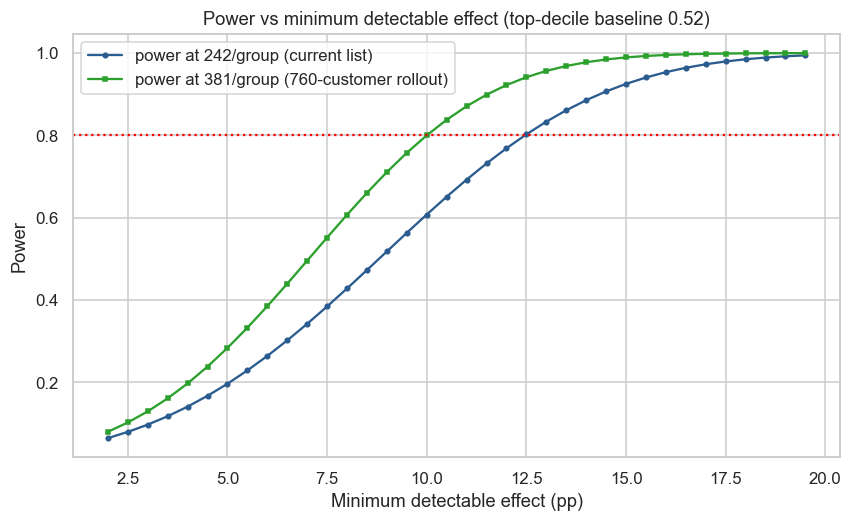

In [22]:
from scipy import stats
from math import ceil

def n_per_group(p0, delta, alpha=0.05, power=0.80):
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    p1 = p0 + delta
    return ceil(((za + zb) ** 2 * (p0 * (1 - p0) + p1 * (1 - p1))) / (p1 - p0) ** 2)

def power_at(p0, delta, n):
    za = stats.norm.ppf(0.975)
    p1 = p0 + delta
    return stats.norm.cdf(np.sqrt(n * (p1 - p0) ** 2 / (p0 * (1 - p0) + p1 * (1 - p1))) - za)

p0_all = 1 - te.label_churn.mean()
p0_risk = 1 - 0.4804
print(f"Baselines - all customers repurchase {p0_all:.3f} | top-decile high-risk {p0_risk:.3f}")

rows = []
for dpp in [5, 8, 10, 12, 15]:
    n = n_per_group(p0_risk, dpp / 100)
    rows.append({"MDE (pp)": dpp, "n per group": n, "total customers": 2 * n,
                 "power at 242/group": round(power_at(p0_risk, dpp / 100, 242), 2)})
ab_df = pd.DataFrame(rows)
print(ab_df.to_string(index=False))
print("It is observed that the 485-customer top-decile list, 242 per group, detects a 12pp "
      "lift at only 77 percent power. The experiment must either expand the rollout, about "
      "760 customers detect a 10pp lift at 80 percent power, or accept a directional read.")

fig, ax = plt.subplots(figsize=(9, 5))
mdes = np.arange(0.02, 0.20, 0.005)
ax.plot(mdes * 100, [power_at(p0_risk, d, 242) for d in mdes], marker="o", ms=3, color="#2b5c8f", label="power at 242/group (current list)")
ax.plot(mdes * 100, [power_at(p0_risk, d, 381) for d in mdes], marker="s", ms=3, color="#2ca02c", label="power at 381/group (760-customer rollout)")
ax.axhline(0.80, color="red", ls=":")
ax.set(title="Power vs minimum detectable effect (top-decile baseline 0.52)",
       xlabel="Minimum detectable effect (pp)", ylabel="Power")
ax.legend(); plt.show()

### 8.3 Recommended design

* **Population.** The top decile of the churn score, about 485 customers, expanded to the
  top three deciles, about 1,455 customers, if statistical power requires it.
* **Allocation.** 50/50 stratified by score decile, with a fixed 90-day readout.
* **Outcome.** 90-day repurchase rate as the primary metric; average spend, support
  tickets, and return rate as guardrails.
* **Interpretation.** A detected lift of 10pp or more on the high-risk cohort, at 80
  percent power, validates the response assumption. A smaller detected lift requires a
  larger rollout, so the experiment and the response curve should be read together.

## 9. Recommendations and Reproducibility

### 8.1 Recommendations

1. **Deploy the churn score weekly in the CRM.** The score reaches a ROC-AUC of 0.898
   and a Precision at the top-10% decile of about 49 percent, roughly five times the
   base rate. The top-decile list, about 485 customers, is routed to the win-back
   workflow.
2. **Allocate offers with the exact MILP.** At a 10,000 dollar budget the exact
   allocation retains about 202,403 dollars, a projected ROAS of 20.24 (not a measured
   return), versus 80,539 dollars for the greedy heuristic and 67,516 dollars for naive
   spend, because the greedy heuristic was measured about 60.2 percent below the
   optimal solution (values from the executed run; run-to-run varies with the solver).
3. **Tier the win-back by segment.** Premium offers for at-risk High-Value Loyalists,
   low-cost coupons for Light and Disengaged shoppers, and category cross-sell for
   Occasional shoppers.
4. **Add early-warning triggers.** A declining average order value or a recency above
   60 days flags a customer weeks before the 90-day silence.
5. **Weight urgency with survival.** The survival probabilities S(30) and S(90)
   prioritize soon-to-lapse high-value customers inside the optimizer.
6. **A/B test the response curve before scale.** Randomize 50/50 within the top-decile
   list, measure the 90-day repurchase lift, then run a rolling monthly retrain loop.

### 8.2 Reproducibility

Run `build_dataset.py`, `build_notebook.py`, `execute_notebook.py` and
`train_models.py` in order, then `streamlit run dashboard.py`. All random seeds are 42.
Environment: Python 3.11, pandas 2.2, scikit-learn 1.5, xgboost 3.2, scikit-survival
0.28, shap 0.51.

### 8.3 References

1. Berke, A., Calacci, D., Mahari, R., Yabe, T., Larson, K. and Pentland, S. (2024).
   Open e-commerce 1.0, five years of crowdsourced U.S. Amazon purchase histories with
   user demographics. Scientific Data, 11. DOI 10.1038/s41597-024-03329-6.
2. Predicting customer churn with extreme gradient boosting and temporal data. arXiv.
3. A rolling-window framework for churn prediction and behavioral driver
   identification. arXiv.
4. ChOracle, a unified statistical framework for churn prediction. arXiv.
5. Lundberg, S. and Lee, S.-I. (2017). A unified approach to interpreting model
   predictions. NeurIPS. (SHAP)

